# 02 — Classical system identification on the full corruption grid

Methods (all on the same degree-2 monomial library, in nondimensional coordinates $z=x/s$, $\tau=t/t_{\rm char}$):

| | estimator | derivative information |
|---|---|---|
| **C1** | dense least squares | second-order central differences |
| **C2-FD** | SINDy / STLSQ | central differences |
| **C2-SG** | SINDy / STLSQ | Savitzky–Golay (window selected) |
| **C3** | weak-form SINDy / STLSQ | none (integration by parts against $\phi(t)=(1-s^2)^4$) |

Hyper-parameters (threshold $\lambda$, SG window, test-function half-width) are chosen on the held-out 20% of each experiment by the short-horizon rollout error, taking the sparsest candidate within $5\%$ (plus an absolute $10^{-4}$) of the best. No method sees the true coefficients.

Grid: 2 systems × 4 sampling intervals × 6 noise levels × 3 seeds, plus an irregular-sampling condition, the predator–prey control and a design ablation.

In [1]:
import sys, os, time, pickle
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import experiment as E, plotting as P
from src.sweeps import classical_job, run_parallel, save_rows
from src.library import PolyLibrary
P.setup()
MET = "../results/metrics"
os.makedirs(MET, exist_ok=True)
SEEDS = [0, 1, 2]

In [2]:
jobs = [(name, r, eps, seed, {}) for name in ["lorenz", "lv4"] for r in E.DT_RATIOS
        for eps in E.NOISES for seed in SEEDS]
# irregular sampling at the central interval
jobs += [(name, 1/15, eps, seed, dict(irregular=True)) for name in ["lorenz", "lv4"]
         for eps in [0.0, 0.01, 0.05] for seed in SEEDS]
# non-chaotic control
jobs += [("lv2", r, eps, 0, {}) for r in E.DT_RATIOS for eps in [0.0, 0.01, 0.05]]
print(len(jobs), "configurations")
t0 = time.time()
rows = run_parallel(classical_job, jobs, workers=2, log_every=25)
print(f"elapsed {(time.time() - t0) / 60:.1f} min")
df, coefs = save_rows(rows, f"{MET}/classical_grid.csv", f"{MET}/classical_coefs.pkl")
print("failed rows:", int(df["error"].notna().sum()) if "error" in df else 0)
df.head()

174 configurations


25/174 jobs done


50/174 jobs done


75/174 jobs done


100/174 jobs done


125/174 jobs done


150/174 jobs done


174/174 jobs done


elapsed 18.4 min
failed rows: 0


,system,method,dt,dt_ratio,noise,seed,irregular,fit_time,coef_err,precision,...,vpt_ood_sd,nrmse1_ood,diverged_ood,diverged_long,w1,lyap_est,lam,val_err,window,half_width
0,lorenz,C1-OLS,0.01,0.013333,0.0,0,False,0.002685,1.251928e-02,0.233333,...,2.781909,0.162186,0.0,0.0,0.035537,0.932001,NaN,NaN,NaN,NaN
1,lorenz,C2-SINDy-FD,0.01,0.013333,0.0,0,False,0.491796,6.901019e-03,1.000000,...,3.629665,0.027176,0.0,0.0,0.042541,0.893293,0.051557,8.764080e-05,NaN,NaN
2,lorenz,C2-SINDy-SG,0.01,0.013333,0.0,0,False,2.954419,1.013741e-04,1.000000,...,2.784207,0.000629,0.0,0.0,0.120287,0.915710,0.001854,1.474211e-08,5.0,NaN
3,lorenz,C3-WSINDy,0.01,0.013333,0.0,0,False,2.331474,5.651796e-08,1.000000,...,2.864810,0.000220,0.0,0.0,0.165796,0.897230,0.001854,2.983750e-11,NaN,0.75
4,lorenz,C1-OLS,0.01,0.013333,0.0,1,False,0.002356,1.386242e-02,0.233333,...,2.651124,0.150200,0.0,0.0,0.101536,0.910195,NaN,NaN,NaN,NaN


## Design ablation: one orbit versus four perturbed experiments

Same record length, same estimators; LV4 is where the conditioning of the library matters.

In [3]:
abl_jobs = [(name, 1/75, eps, seed, dict(n_exp=1, pert=0.0)) for name in ["lorenz", "lv4"]
            for eps in [0.0, 0.01, 0.02] for seed in SEEDS]
abl = run_parallel(classical_job, abl_jobs, workers=2, log_every=50)
df_abl, _ = save_rows(abl, f"{MET}/classical_design_ablation.csv", f"{MET}/classical_design_ablation_coefs.pkl")
ref = df[(df.dt_ratio.round(4) == round(1/75, 4)) & (df.noise.isin([0.0, 0.01, 0.02])) & (~df.irregular)]
comp = pd.concat([df_abl.assign(design="single orbit"), ref.assign(design="4 experiments")])
tab = comp.groupby(["system", "design", "noise", "method"])["coef_err"].median().unstack("method")
tab.round(4)

18/18 jobs done


method                      C1-OLS  C2-SINDy-FD  C2-SINDy-SG  C3-WSINDy
system design        noise                                             
lorenz 4 experiments 0.00   0.0125       0.0059       0.0001     0.0000
                     0.01   0.0391       0.0067       0.0050     0.0004
                     0.02   0.0863       0.0088       0.0068     0.0006
       single orbit  0.00   0.0177       0.0063       0.0001     0.0000
                     0.01   0.0331       0.0090       0.0075     0.0031
                     0.02   0.0748       0.0163       0.0263     0.0047
lv2    4 experiments 0.00   0.0093       0.0039       0.0001     0.0000
                     0.01   0.0103       0.0050       0.0012     0.0028
lv4    4 experiments 0.00   0.1848       0.0052       0.0004     0.0000
                     0.01   1.6250       1.5559       1.0633     1.5334
                     0.02   3.2207       3.2207       1.2797     2.6073
       single orbit  0.00   0.3062       0.1547       0.0001     0.0000
                     0.01   3.0155       2.3302       3.1674     2.2393
                     0.02   1.8851       1.0136       2.4263     2.6674

## Coefficient error over the grid (median over seeds)

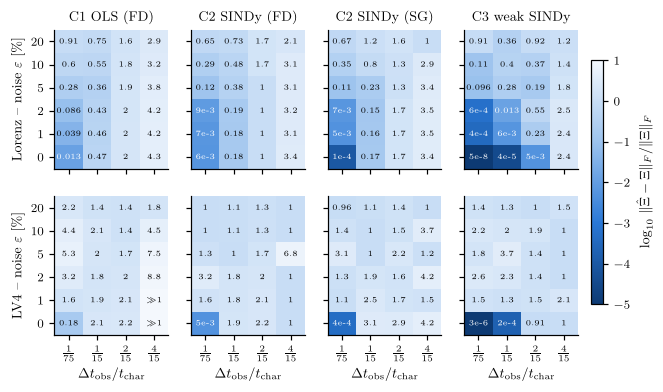

In [4]:
main = df[(~df.irregular) & df.system.isin(["lorenz", "lv4"])].copy()
methods = ["C1-OLS", "C2-SINDy-FD", "C2-SINDy-SG", "C3-WSINDy"]
fig, axes = plt.subplots(2, 4, figsize=(7.4, 3.6), sharex=True, sharey=True)
for i, name in enumerate(["lorenz", "lv4"]):
    for j, m in enumerate(methods):
        sub = main[(main.system == name) & (main.method == m)]
        piv = sub.groupby(["noise", "dt_ratio"])["coef_err"].median().unstack("dt_ratio")
        A = np.log10(np.clip(piv.values, 1e-6, 10))
        ax = axes[i, j]
        im = ax.imshow(A, origin="lower", cmap=P.SEQ.reversed(), vmin=-5, vmax=1, aspect="auto")
        for (a, b), v in np.ndenumerate(piv.values):
            lab = (f"{v:.0e}".replace("e-0", "e-") if v < 0.01 else f"{v:.2g}") if v < 9.5 else r"$\gg$1"
            ax.text(b, a, lab, ha="center", va="center", fontsize=5.2,
                    color="white" if np.log10(max(v, 1e-6)) < -1.5 else "black")
        ax.set_xticks(range(4)); ax.set_xticklabels([r"$\frac{1}{75}$", r"$\frac{1}{15}$", r"$\frac{2}{15}$", r"$\frac{4}{15}$"])
        ax.set_yticks(range(len(piv.index))); ax.set_yticklabels([f"{int(100*e)}" for e in piv.index])
        ax.grid(False)
        if i == 0: ax.set_title(P.LABELS[m])
        if i == 1: ax.set_xlabel(r"$\Delta t_{\rm obs}/t_{\rm char}$")
        if j == 0: ax.set_ylabel(("Lorenz" if name == "lorenz" else "LV4") + r" -- noise $\varepsilon$ [\%]")
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cb.set_label(r"$\log_{10}\,\|\hat\Xi-\Xi\|_F/\|\Xi\|_F$")
P.save(fig, "fig02_classical_heatmaps")
plt.show()

In [5]:
summary = (main.groupby(["system", "method", "dt_ratio", "noise"])
           [["coef_err", "f1", "vpt_id", "vpt_ood", "w1", "diverged_long"]].median().reset_index())
summary.to_csv(f"{MET}/classical_summary.csv", index=False)
summary[(summary.noise == 0.01)].pivot_table(index=["system", "dt_ratio"], columns="method", values="coef_err").round(4)

method            C1-OLS  C2-SINDy-FD  C2-SINDy-SG  C3-WSINDy
system dt_ratio                                              
lorenz 0.013333   0.0391       0.0067       0.0050     0.0004
       0.066667   0.4586       0.1831       0.1626     0.0061
       0.133333   1.9864       1.0000       1.7140     0.2321
       0.266667   4.2500       3.0947       3.4742     2.4305
lv4    0.013333   1.6250       1.5559       1.0633     1.5334
       0.066667   1.9102       1.8011       2.5085     1.3232
       0.133333   2.1417       2.0917       1.7211     1.4592
       0.266667  13.0030       1.0000       1.5430     2.1297

## Irregular sampling and the predator–prey control

In [6]:
irr = df[df.irregular].groupby(["system", "noise", "method"])["coef_err"].median().unstack("method")
reg = df[(~df.irregular) & (df.dt_ratio.round(4) == round(1/15, 4)) & df.noise.isin([0, 0.01, 0.05])
         & df.system.isin(["lorenz", "lv4"])].groupby(["system", "noise", "method"])["coef_err"].median().unstack("method")
print("irregular sampling (same mean density as dt = t_char/15):"); display(irr.round(4))
print("regular sampling:"); display(reg.round(4))
lv2 = df[df.system == "lv2"].pivot_table(index=["dt_ratio", "noise"], columns="method", values="coef_err")
print("predator-prey control:"); display(lv2.round(4))

irregular sampling (same mean density as dt = t_char/15):


method        C1-OLS  C2-SINDy-FD  C3-WSINDy
system noise                                
lorenz 0.00   0.3713       0.2391     1.0000
       0.01   1.4247       0.8508     1.6330
       0.05   4.5878       1.0000     1.1506
lv4    0.00   2.4756       2.3039     1.0000
       0.01   4.0489       2.1672     1.0000
       0.05   7.8075       1.0000     1.0000

regular sampling:


method        C1-OLS  C2-SINDy-FD  C2-SINDy-SG  C3-WSINDy
system noise                                             
lorenz 0.00   0.4748       0.1801       0.1732     0.0000
       0.01   0.4586       0.1831       0.1626     0.0061
       0.05   0.3611       0.3769       0.2259     0.2803
lv4    0.00   2.1447       1.8963       3.1314     0.0002
       0.01   1.9102       1.8011       2.5085     1.3232
       0.05   2.0129       1.0000       1.0000     3.7048

predator-prey control:


method          C1-OLS  C2-SINDy-FD  C2-SINDy-SG  C3-WSINDy
dt_ratio noise                                             
0.013333 0.00   0.0093       0.0039       0.0001     0.0000
         0.01   0.0103       0.0050       0.0012     0.0028
         0.05   0.0234       0.0116       0.0075     0.0019
0.066667 0.00   0.1863       0.1481       0.0143     0.0001
         0.01   0.1867       0.1513       0.0157     0.0006
         0.05   0.1950       0.1401       0.0229     0.0479
0.133333 0.00   0.9052       1.0814       0.8931     0.7066
         0.01   0.9066       1.0813       0.8941     0.7051
         0.05   0.9112       1.0810       0.8981     0.7000
0.266667 0.00   1.8410       1.4926       1.1785     1.2225
         0.01   1.8404       1.4955       1.1788     1.2218
         0.05   1.8182       1.4957       1.1792     1.2162

## Example of recovered equations (Lorenz, $\Delta t_{\rm obs}=t_{\rm char}/15$, $\varepsilon=1\%$, seed 0)

In [7]:
s = E.get_sys("lorenz"); lib = PolyLibrary(3, 2, s.symbols)
for m in methods:
    Xi = coefs[("lorenz", m, round(1/15, 5), 0.01, 0, False)]
    print(f"[{m}]"); print(lib.pretty(Xi, s.symbols, tol=1e-12, fmt="{:+.3f}")); print()

[C1-OLS]
dx/dt = +7.375 -14.005 x +12.443 y -0.857 z -0.077 x^2 +0.046 x y +0.128 x z +0.002 y^2 -0.088 y z +0.023 z^2
dy/dt = +16.667 +19.208 x +2.555 y -2.019 z -0.190 x^2 +0.149 x y -0.754 x z -0.019 y^2 -0.079 y z +0.054 z^2
dz/dt = +2.680 -0.942 x +0.560 y -2.215 z +0.471 x^2 +0.365 x y +0.025 x z +0.198 y^2 -0.017 y z -0.032 z^2

[C2-SINDy-FD]
dx/dt = -13.666 x +12.293 y +0.120 x z -0.084 y z
dy/dt = +14.684 +19.222 x +2.551 y -1.791 z -0.147 x^2 +0.096 x y -0.755 x z -0.079 y z +0.047 z^2
dz/dt = -1.885 z +0.500 x^2 +0.349 x y +0.197 y^2 -0.040 z^2

[C2-SINDy-SG]
dx/dt = -11.535 x +10.956 y +0.044 x z -0.029 y z
dy/dt = +7.922 +24.727 x +0.739 y -1.038 z -0.114 x^2 +0.075 x y -0.910 x z -0.044 y z +0.029 z^2
dz/dt = -2.649 z +0.993 x y

[C3-WSINDy]
dx/dt = -10.011 x +9.991 y
dy/dt = +28.057 x -1.026 y -1.001 x z
dz/dt = -2.666 z +1.001 x y

